# Stroke — Paper replication

This notebook replicates the analysis described by Wu et al., *A Machine Learning-Based Model for Stroke Prediction*, DOI: [10.54254/2755-2721/78/20240645](https://doi.org/10.54254/2755-2721/78/20240645).

It compares logistic regression, Decision Tree, Random Forest, SVM, KNN, XGBoost and a deep neural network before and after feature selection, with performance tables and paper-style figures.

The implementation uses a stratified 80/20 split. BMI imputation, correlation-based feature selection and scaling are learned from the training data only. Full-dataset correlation figures are descriptive and do not determine the predictive feature set.

Test-performance rankings are descriptive. Class-balanced logistic regression is pre-specified separately for the XAI extension.

In [1]:
# Dependencies are installed from requirements-xai-lock.txt, not here.

In [2]:
# The versioned local Stroke CSV is used; no online fetch is required.

In [3]:
# XGBoost is provided by the reproducible project environment.

In [4]:
# imbalanced-learn is provided by the reproducible project environment.

In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, recall_score, roc_curve, auc

from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

from seaborn import heatmap
import seaborn as sns

import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

file_path = "../../data\\stroke\\healthcare-dataset-stroke-data.csv"

df_corr = pd.read_csv(file_path)

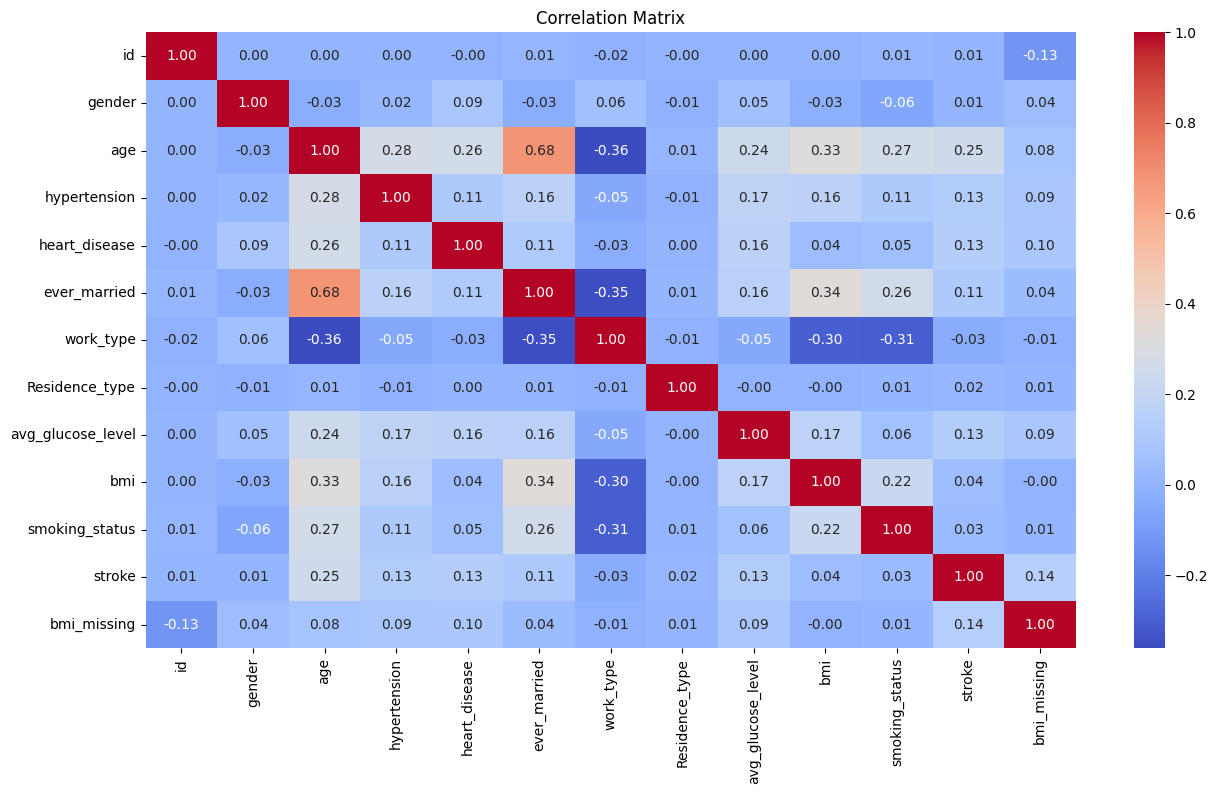

In [6]:
# remove 'Other'
df_corr = df_corr[df_corr['gender'] != 'Other']

# creation of bmi_missing -> correct dataframe
df_corr['bmi_missing'] = df_corr['bmi'].isna().astype(int)

# fill BMI after flag
df_corr['bmi'] = df_corr['bmi'].fillna(df_corr['bmi'].mean())

# conversion categorical -> numeric
df_corr['gender'] = df_corr['gender'].map({'Male': 1, 'Female': 0})
df_corr['ever_married'] = df_corr['ever_married'].map({'Yes': 1, 'No': 0})
df_corr['Residence_type'] = df_corr['Residence_type'].map({'Urban': 1, 'Rural': 0})

df_corr['work_type'] = df_corr['work_type'].astype('category').cat.codes
df_corr['smoking_status'] = df_corr['smoking_status'].astype('category').cat.codes

# correlation matrix
corr_matrix = df_corr.corr()

plt.figure(figsize=(15,8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')

plt.title("Correlation Matrix")
plt.show()

In [7]:
df = pd.read_csv(file_path)
df = df[df['gender'] != 'Other'].copy()
df['age'] = df['age'].astype(int)

y = df['stroke'].copy()
X_raw = df.drop(columns=['stroke', 'id']).copy()

# Split before imputation, encoding, feature selection, and scaling.
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.2, random_state=42, stratify=y
)

for part in (X_train_raw, X_test_raw):
    part['bmi_missing'] = part['bmi'].isna().astype(int)

train_bmi_mean = X_train_raw['bmi'].mean()
X_train_raw['bmi'] = X_train_raw['bmi'].fillna(train_bmi_mean)
X_test_raw['bmi'] = X_test_raw['bmi'].fillna(train_bmi_mean)

categorical_cols = [
    'gender', 'smoking_status', 'Residence_type',
    'work_type', 'ever_married'
]
X_train_encoded = pd.get_dummies(
    X_train_raw, columns=categorical_cols, drop_first=False
)
X_test_encoded = pd.get_dummies(
    X_test_raw, columns=categorical_cols, drop_first=False
).reindex(columns=X_train_encoded.columns, fill_value=0)

# Learn the correlation-based feature set from training data only.
training_for_selection = X_train_encoded.copy()
training_for_selection['stroke'] = y_train.to_numpy()
training_correlations = training_for_selection.corr(numeric_only=True)['stroke'].abs()
selected_features = training_correlations[
    (training_correlations > 0.1)
    & (training_correlations.index != 'stroke')
].index.tolist()

X_train_full = X_train_encoded
X_test_full = X_test_encoded
X_train_sel = X_train_encoded[selected_features]
X_test_sel = X_test_encoded[selected_features]

In [8]:
print('Training rows:', len(X_train_full))
print('Test rows:', len(X_test_full))
print('Full features:', X_train_full.shape[1])
print('Training-selected features:', selected_features)

Training rows: 4087
Test rows: 1022
Full features: 21
Training-selected features: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi_missing', 'ever_married_No', 'ever_married_Yes']


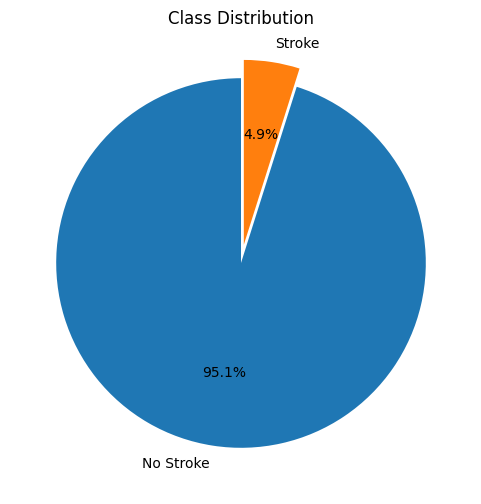

In [9]:
counts = y.value_counts()

labels = ['No Stroke', 'Stroke']
sizes = counts.values

plt.figure(figsize=(6,6))
plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90,
    explode=[0, 0.1]
)

plt.title("Class Distribution")
plt.show()

In [10]:
scaler_full = StandardScaler()
X_train_full = pd.DataFrame(
    scaler_full.fit_transform(X_train_full),
    columns=X_train_encoded.columns, index=X_train_encoded.index
)
X_test_full = pd.DataFrame(
    scaler_full.transform(X_test_full),
    columns=X_train_encoded.columns, index=X_test_encoded.index
)

scaler_sel = StandardScaler()
X_train_sel = pd.DataFrame(
    scaler_sel.fit_transform(X_train_sel),
    columns=selected_features, index=X_train_encoded.index
)
X_test_sel = pd.DataFrame(
    scaler_sel.transform(X_test_sel),
    columns=selected_features, index=X_test_encoded.index
)

In [11]:

def evaluate(y_true, y_pred, y_scores):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    return acc, f1, recall, fpr, tpr, roc_auc

In [12]:
def run_models(X_train, X_test, y_train, y_test):
    from imblearn.over_sampling import SMOTE

    # SMOTE (only on training set)
    #sm = SMOTE(random_state=42)
    #X_train, y_train = sm.fit_resample(X_train, y_train)

    results = {}

    # Logistic Regression
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    y_pred = lr.predict(X_test)
    y_scores = lr.predict_proba(X_test)[:,1]
    results["Logistic Regression"] = evaluate(y_test, y_pred, y_scores)

    # Decision Tree
    dt = DecisionTreeClassifier()
    dt.fit(X_train, y_train)
    y_pred = dt.predict(X_test)
    y_scores = dt.predict_proba(X_test)[:,1]
    results["Decision Tree"] = evaluate(y_test, y_pred, y_scores)

    # Random Forest
    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_test)
    y_scores = rf.predict_proba(X_test)[:,1]
    results["Random Forest"] = evaluate(y_test, y_pred, y_scores)

    # SVM
    svm = SVC(probability=True)
    svm.fit(X_train, y_train)
    y_pred = svm.predict(X_test)
    y_scores = svm.predict_proba(X_test)[:,1]
    results["SVM"] = evaluate(y_test, y_pred, y_scores)

    # KNN
    knn = KNeighborsClassifier()
    knn.fit(X_train, y_train)
    y_pred = knn.predict(X_test)
    y_scores = knn.predict_proba(X_test)[:,1]
    results["KNN"] = evaluate(y_test, y_pred, y_scores)

    # XGBoost 
    try:
        xgb = XGBClassifier(eval_metric='logloss')
        xgb.fit(X_train, y_train)
        y_pred = xgb.predict(X_test)
        y_scores = xgb.predict_proba(X_test)[:,1]
        results["XGBoost"] = evaluate(y_test, y_pred, y_scores)
    except:
        print("XGBoost not installed")

    return results

In [13]:
results_before = run_models(X_train_full, X_test_full, y_train, y_test)
results_after = run_models(X_train_sel, X_test_sel, y_train, y_test)

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  

In [14]:
def run_dnn(X_train, X_test, y_train, y_test):
    # SMOTE
    #sm = SMOTE(random_state=42)
    #X_train, y_train = sm.fit_resample(X_train, y_train)

    model = Sequential()
    model.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=20, batch_size=50, verbose=0)

    y_scores = model.predict(X_test).ravel()
    y_pred = (y_scores > 0.5).astype(int)

    return evaluate(y_test, y_pred, y_scores)

In [15]:
results_before["DNN"] = run_dnn(X_train_full, X_test_full, y_train, y_test)
results_after["DNN"] = run_dnn(X_train_sel, X_test_sel, y_train, y_test)

c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [16]:
def plot_results(results, title):
    plot_models = [
        "Logistic Regression",
        "SVM",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]

    model_colors = {
        "Logistic Regression": "#4c4a86",  # blue
        "SVM": "#6783c1",                  # orange
        "KNN": "#dbe4f0",                  # green
        "Decision Tree": "#e5a39b",        # red
        "Random Forest": "#514c88",        # purple
        "XGBoost": "#6e89c9"               # brown
    }

    colors = [model_colors[m] for m in plot_models]

    acc = [results[m][0] for m in plot_models]
    f1 = [results[m][1] for m in plot_models]
    recall = [results[m][2] for m in plot_models]
    aucs = [results[m][5] for m in plot_models]

    fig, axs = plt.subplots(2, 2, figsize=(12, 10))

    axs[0, 0].bar(plot_models, aucs, color=colors)
    axs[0, 0].set_title("AUC Comparison")
    axs[0, 0].set_ylabel("AUC")

    axs[0, 1].bar(plot_models, acc, color=colors)
    axs[0, 1].set_title("Accuracy Comparison")
    axs[0, 1].set_ylabel("Accuracy")

    axs[1, 0].bar(plot_models, f1, color=colors)
    axs[1, 0].set_title("F1 Comparison")
    axs[1, 0].set_ylabel("F1")

    axs[1, 1].bar(plot_models, recall, color=colors)
    axs[1, 1].set_title("Recall Comparison")
    axs[1, 1].set_ylabel("Recall")

    for ax in axs.flat:
        ax.tick_params(axis='x', rotation=45)

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

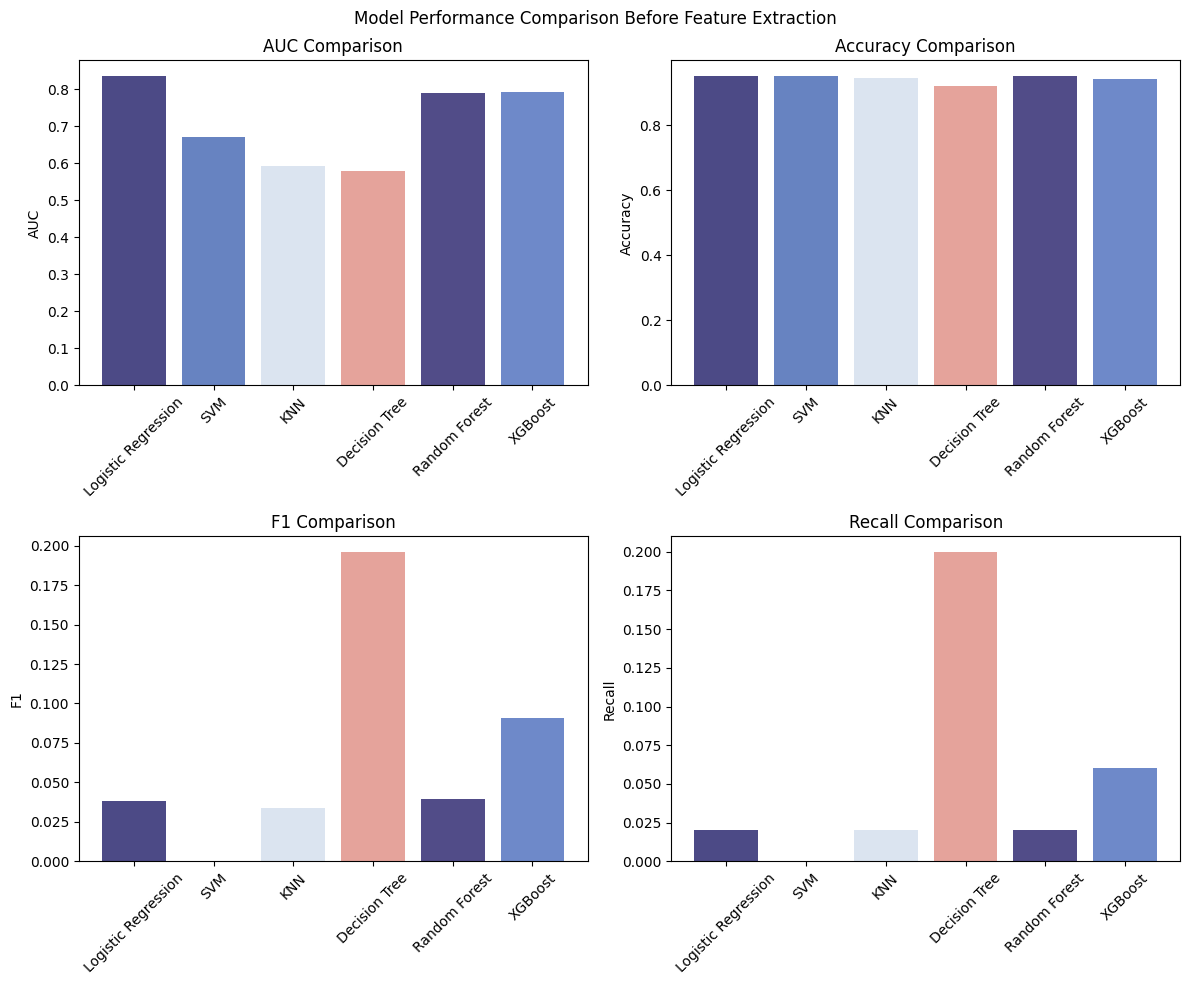

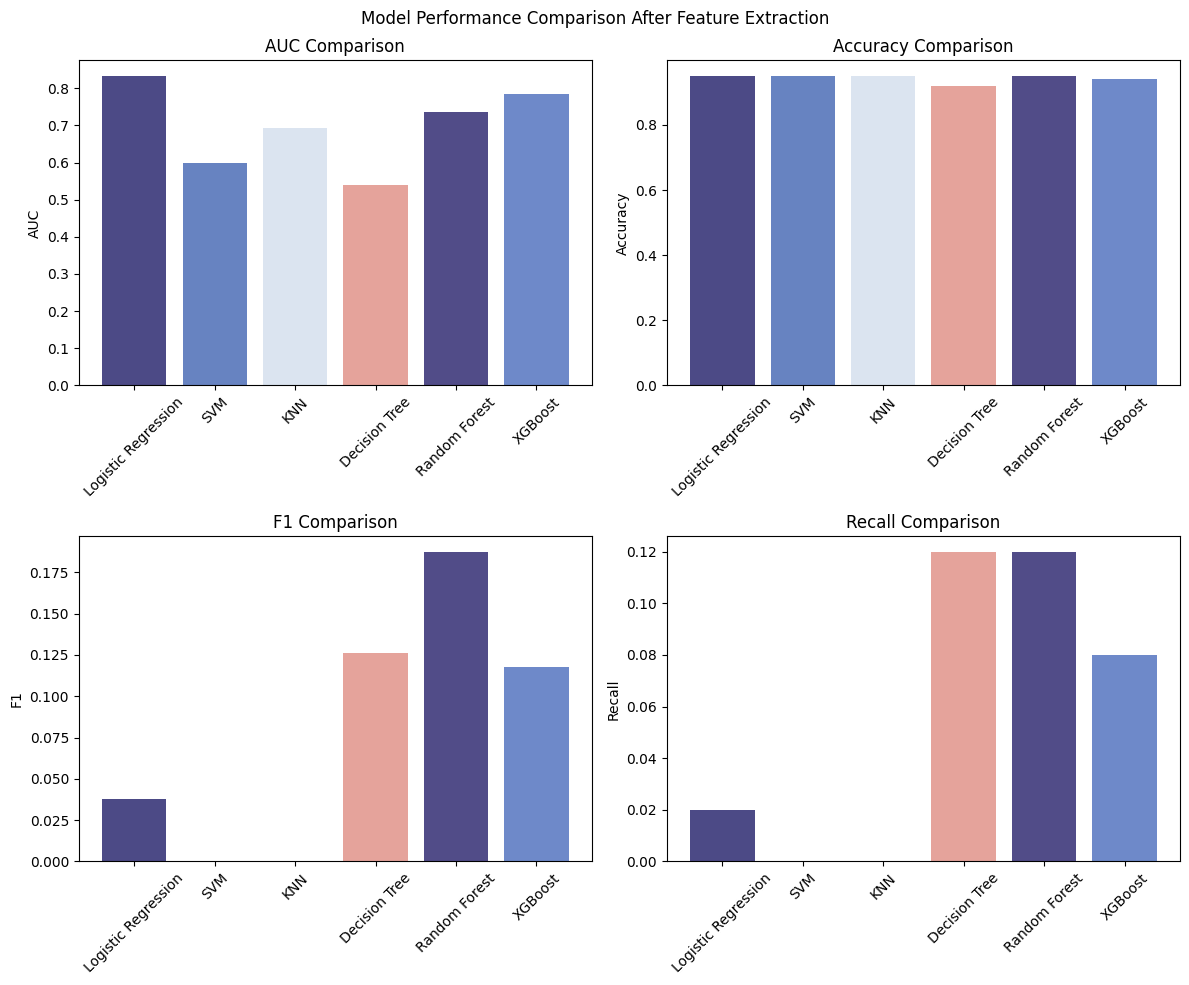

In [17]:
plot_results(results_before, "Model Performance Comparison Before Feature Extraction")
plot_results(results_after, "Model Performance Comparison After Feature Extraction")

In [18]:
import pandas as pd

dnn_before = results_before["DNN"]
dnn_after = results_after["DNN"]

dnn_table = pd.DataFrame({
    "Metric": ["Accuracy", "AUC"],
    "Before Feature Extraction": [round(dnn_before[0], 4), round(dnn_before[5], 4)],
    "After Feature Extraction": [round(dnn_after[0], 4), round(dnn_after[5], 4)]
})

print(dnn_table)

     Metric  Before Feature Extraction  After Feature Extraction
0  Accuracy                     0.9501                    0.9481
1       AUC                     0.8079                    0.8330


## Repeated paper-style comparison (existing seeded run)

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_curve, auc

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

# optional for reproducibility
np.random.seed(42)
random.seed(42)
tf.random.set_seed(42)

# The leakage-controlled train/test matrices created above are reused.
# Reproducibility seeds apply to the repeated model comparison below.

In [20]:
# Split, training-only imputation, training-only feature selection, and
# training-only scaling were completed once above.

In [21]:
# -----------------------------
# 4. Evaluation functions
# -----------------------------
def evaluate(y_true, y_pred, y_scores):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    fpr, tpr, _ = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    return acc, f1, recall, fpr, tpr, roc_auc


In [22]:
def run_models(X_train, X_test, y_train, y_test):
    results = {}
    trained_models = {}

    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    trained_models["Logistic Regression"] = lr
    y_pred = lr.predict(X_test)
    y_scores = lr.predict_proba(X_test)[:, 1]
    results["Logistic Regression"] = evaluate(y_test, y_pred, y_scores)

    dt = DecisionTreeClassifier()
    dt.fit(X_train, y_train)
    trained_models["Decision Tree"] = dt
    y_pred = dt.predict(X_test)
    y_scores = dt.predict_proba(X_test)[:, 1]
    results["Decision Tree"] = evaluate(y_test, y_pred, y_scores)

    rf = RandomForestClassifier()
    rf.fit(X_train, y_train)
    trained_models["Random Forest"] = rf
    y_pred = rf.predict(X_test)
    y_scores = rf.predict_proba(X_test)[:, 1]
    results["Random Forest"] = evaluate(y_test, y_pred, y_scores)

    svm = SVC(probability=True)
    svm.fit(X_train, y_train)
    trained_models["SVM"] = svm
    y_pred = svm.predict(X_test)
    y_scores = svm.predict_proba(X_test)[:, 1]
    results["SVM"] = evaluate(y_test, y_pred, y_scores)

    knn = KNeighborsClassifier()
    knn.fit(X_train, y_train)
    trained_models["KNN"] = knn
    y_pred = knn.predict(X_test)
    y_scores = knn.predict_proba(X_test)[:, 1]
    results["KNN"] = evaluate(y_test, y_pred, y_scores)

    xgb = XGBClassifier(eval_metric='logloss')
    xgb.fit(X_train, y_train)
    trained_models["XGBoost"] = xgb
    y_pred = xgb.predict(X_test)
    y_scores = xgb.predict_proba(X_test)[:, 1]
    results["XGBoost"] = evaluate(y_test, y_pred, y_scores)

    return results, trained_models

results_before, models_before = run_models(X_train_full, X_test_full, y_train, y_test)
results_after, models_after = run_models(X_train_sel, X_test_sel, y_train, y_test)

In [23]:
performance = pd.DataFrame({
    "Model": results_after.keys(),
    "AUC": [v[5] for v in results_after.values()]
})

performance = performance.sort_values(
    "AUC",
    ascending=False
)

print(performance)

                 Model       AUC
0  Logistic Regression  0.833807
5              XGBoost  0.785792
2        Random Forest  0.719619
4                  KNN  0.693354
3                  SVM  0.598807
1        Decision Tree  0.519938


In [24]:
test_auc_leader = performance.iloc[0]["Model"]
print(f"Highest observed test AUC (descriptive only): {test_auc_leader}")

Highest observed test AUC (descriptive only): Logistic Regression


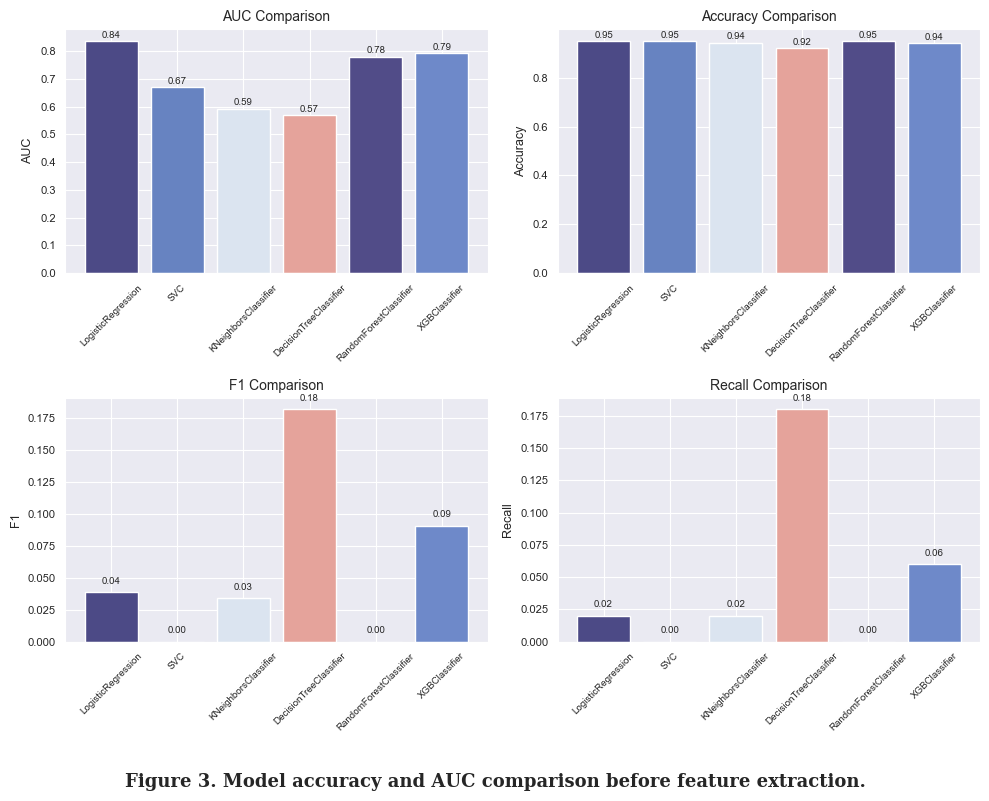

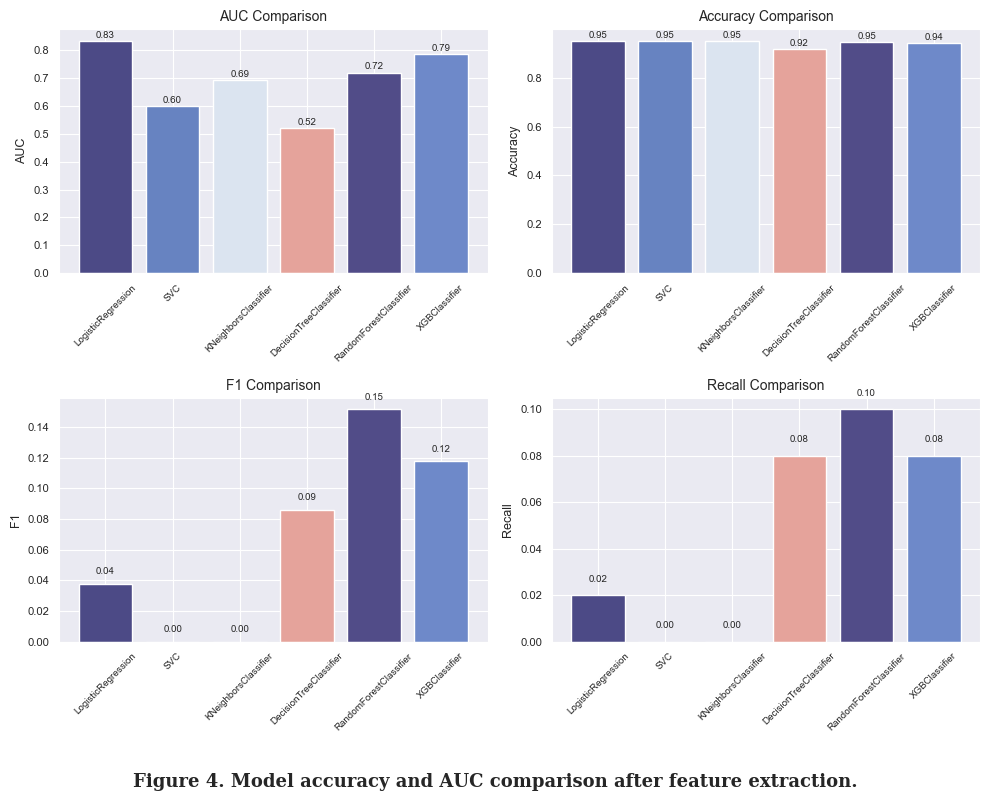

In [25]:
# -----------------------------
# 5. Paper-style plotting
# -----------------------------
def plot_results_paper_style(results, caption_text):
    sns.set_style("darkgrid")

    plot_models = [
        "Logistic Regression",
        "SVM",
        "KNN",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ]

    label_map = {
        "Logistic Regression": "LogisticRegression",
        "SVM": "SVC",
        "KNN": "KNeighborsClassifier",
        "Decision Tree": "DecisionTreeClassifier",
        "Random Forest": "RandomForestClassifier",
        "XGBoost": "XGBClassifier"
    }

    display_labels = [label_map[m] for m in plot_models]

    model_colors = [
        "#4c4a86",
        "#6783c1",
        "#dbe4f0",
        "#e5a39b",
        "#514c88",
        "#6e89c9"
    ]

    acc = [results[m][0] for m in plot_models]
    f1 = [results[m][1] for m in plot_models]
    recall = [results[m][2] for m in plot_models]
    aucs = [results[m][5] for m in plot_models]

    fig, axs = plt.subplots(2, 2, figsize=(10, 8))

    metric_info = [
        ("AUC Comparison", aucs, "AUC"),
        ("Accuracy Comparison", acc, "Accuracy"),
        ("F1 Comparison", f1, "F1"),
        ("Recall Comparison", recall, "Recall")
    ]

    for ax, (title, values, ylabel) in zip(axs.flat, metric_info):
        bars = ax.bar(display_labels, values, color=model_colors)
        ax.set_title(title, fontsize=10)
        ax.set_ylabel(ylabel, fontsize=9)
        ax.tick_params(axis='x', rotation=45, labelsize=7)
        ax.tick_params(axis='y', labelsize=8)

        for bar, val in zip(bars, values):
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.005,
                f"{val:.2f}",
                ha='center',
                va='bottom',
                fontsize=7
            )

    plt.figtext(
        0.5, 0.01,
        caption_text,
        ha='center',
        fontsize=13,
        fontweight='bold',
        family='serif'
    )

    plt.tight_layout(rect=[0, 0.06, 1, 1])
    plt.show()

plot_results_paper_style(
    results_before,
    "Figure 3. Model accuracy and AUC comparison before feature extraction."
)

plot_results_paper_style(
    results_after,
    "Figure 4. Model accuracy and AUC comparison after feature extraction."
)


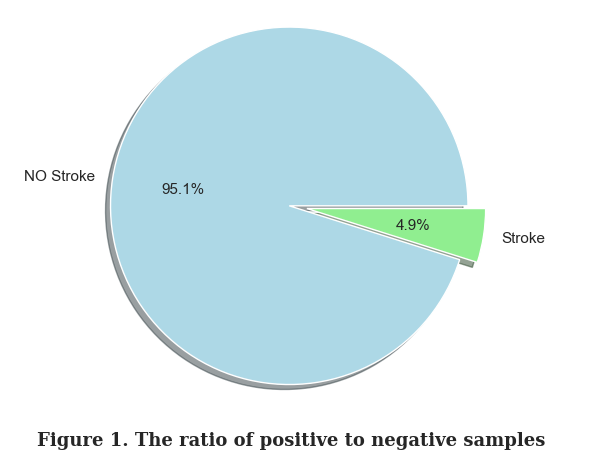

In [26]:
counts = y.value_counts().sort_index()
# Assuming 0 = No Stroke, 1 = Stroke
sizes = [counts[0], counts[1]]
labels = ['NO Stroke', 'Stroke']
colors = ['#add8e6', '#90ee90']  # light blue, light green

fig, ax = plt.subplots(figsize=(6.2, 4.6))

wedges, texts, autotexts = ax.pie(
    sizes,
    labels=labels,
    colors=colors,
    autopct='%1.1f%%',
    startangle=0,
    explode=(0, 0.1),
    shadow=True,
    textprops={'fontsize': 11}
)

ax.axis('equal')

plt.figtext(
    0.5, 0.02,
    'Figure 1. The ratio of positive to negative samples',
    ha='center',
    fontsize=13,
    fontweight='bold',
    family='serif'
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()


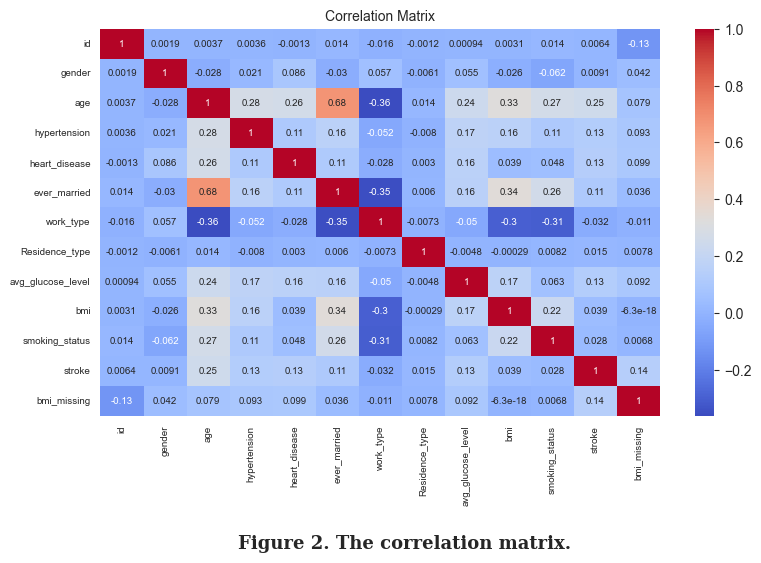

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = "../../data/stroke/healthcare-dataset-stroke-data.csv"
df_corr = pd.read_csv(file_path)

# Remove 'Other'
df_corr = df_corr[df_corr['gender'] != 'Other'].copy()

# Create bmi_missing
df_corr['bmi_missing'] = df_corr['bmi'].isna().astype(int)

# Fill BMI
df_corr['bmi'] = df_corr['bmi'].fillna(df_corr['bmi'].mean())

# Convert categorical to numeric
df_corr['gender'] = df_corr['gender'].map({'Male': 1, 'Female': 0})
df_corr['ever_married'] = df_corr['ever_married'].map({'Yes': 1, 'No': 0})
df_corr['Residence_type'] = df_corr['Residence_type'].map({'Urban': 1, 'Rural': 0})
df_corr['work_type'] = df_corr['work_type'].astype('category').cat.codes
df_corr['smoking_status'] = df_corr['smoking_status'].astype('category').cat.codes

corr_matrix = df_corr.corr()

fig, ax = plt.subplots(figsize=(8.2, 5.6))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2g",
    cmap="coolwarm",
    cbar=True,
    annot_kws={"size": 7},
    ax=ax
)

ax.set_title("Correlation Matrix", fontsize=10)
ax.tick_params(axis='x', labelrotation=90, labelsize=7)
ax.tick_params(axis='y', labelsize=7)

plt.figtext(
    0.5, 0.01,
    'Figure 2. The correlation matrix.',
    ha='center',
    fontsize=13,
    fontweight='bold',
    family='serif'
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()


In [28]:
# -----------------------------
# 4. DNN evaluation function
# -----------------------------
from sklearn.metrics import accuracy_score, roc_curve, auc

def run_dnn(X_train, X_test, y_train, y_test):
    model = Sequential()
    model.add(Dense(64, activation='relu', input_dim=X_train.shape[1]))
    model.add(Dense(32, activation='relu'))
    model.add(Dense(1, activation='sigmoid'))

    model.compile(optimizer=Adam(), loss='binary_crossentropy', metrics=['accuracy'])

    model.fit(X_train, y_train, epochs=20, batch_size=50, verbose=0)

    y_scores = model.predict(X_test).ravel()
    y_pred = (y_scores > 0.5).astype(int)

    acc = accuracy_score(y_test, y_pred)
    fpr, tpr, _ = roc_curve(y_test, y_scores)
    roc_auc = auc(fpr, tpr)

    return acc, roc_auc

# -----------------------------
# 5. Compute DNN results
# -----------------------------
dnn_before_acc, dnn_before_auc = run_dnn(X_train_full, X_test_full, y_train, y_test)
dnn_after_acc, dnn_after_auc = run_dnn(X_train_sel, X_test_sel, y_train, y_test)

dnn_table = pd.DataFrame({
    "Metric": ["Accuracy", "AUC"],
    "Before Feature Extraction": [round(dnn_before_acc, 4), round(dnn_before_auc, 4)],
    "After Feature Extraction": [round(dnn_after_acc, 4), round(dnn_after_auc, 4)]
})

print(dnn_table)


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


c:\Users\catia\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
     Metric  Before Feature Extraction  After Feature Extraction
0  Accuracy                     0.9511                    0.9481
1       AUC                     0.8080                    0.8323
